# Impianti sportivi da OpenStreetMap e pratica sportiva
**Progetto Big Data for Official Statistics – notebook 03**

Le statistiche ufficiali sullo sport dicono *chi* lo pratica, ma non *dove* ci sono le strutture per praticarlo. **OpenStreetMap (OSM)** è una mappa del mondo costruita dai volontari: contiene campi, palestre e centri sportivi, con aggiornamenti continui e accesso libero. È un tipico esempio di fonte *big data* non tradizionale: enorme, gratuita e tempestiva, ma **non progettata per la statistica**.

**Domanda:** le regioni con più impianti sportivi mappati sono anche quelle dove si fa più sport? E l'offerta di impianti aiuta a spiegare il divario Nord-Sud?

**Dati**
- OSM, conteggi per regione scaricati con `scripts/scarica_osm.py` tramite Overpass API (licenza ODbL). Categorie: campi (`leisure=pitch`), centri sportivi (`sports_centre`), palestre (`fitness_centre`), stadi, piste. Le piscine sono escluse perché in OSM sono soprattutto private.
- ISTAT AVQ: pratica sportiva per regione, media 2022-2024 (stime pesate), e popolazione residente stimata con i pesi campionari 2024.

**Attenzione:** è un confronto **tra regioni** (20 osservazioni). Una correlazione tra regioni non dice nulla sul comportamento delle singole persone (fallacia ecologica).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # vedi notebook 02

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RES = ROOT / "figures", ROOT / "results"

osm = pd.read_csv(ROOT / "data" / "processed" / "osm_impianti_regioni.csv")
dati = pd.read_parquet(ROOT / "data" / "processed" / "avq_sport_2014_2024.parquet")
print("Snapshot OSM:", osm.data_osm.iloc[0])
osm

Snapshot OSM: 2026-10-19T11:34:36Z


,regione,iso,campi,centri_sportivi,palestre,stadi,piste,data_osm
0,Piemonte,IT-21,7758,1271,228,94,373,2026-10-19T11:34:36Z
1,Valle d'Aosta,IT-23,348,81,4,6,12,2026-10-19T11:36:36Z
2,Lombardia,IT-25,16052,2456,602,131,819,2026-10-19T11:36:36Z
3,Trentino-Alto Adige,IT-32,3171,514,94,27,221,2026-10-19T11:37:36Z
4,Veneto,IT-34,8894,2473,195,72,387,2026-10-19T11:38:36Z
5,Friuli-Venezia Giulia,IT-36,2252,1168,81,24,159,2026-10-19T11:39:36Z
6,Liguria,IT-42,2337,416,90,25,75,2026-10-19T11:41:36Z
7,Emilia-Romagna,IT-45,6622,1464,283,104,346,2026-10-19T11:42:39Z
8,Toscana,IT-52,6721,958,210,81,296,2026-10-19T11:43:40Z
9,Umbria,IT-55,1691,209,34,27,61,2026-10-19T11:54:51Z


In [2]:
# Stile grafici (palette di riferimento, modalità chiara)
SUPERFICIE, TESTO, TESTO_2, GRIGLIA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLU, ARANCIO, ACQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": TESTO, "axes.labelcolor": TESTO_2, "xtick.color": TESTO_2, "ytick.color": TESTO_2,
    "axes.edgecolor": GRIGLIA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRIGLIA, "grid.linewidth": 0.8, "lines.linewidth": 2, "legend.frameon": False,
})

def fonte(ax, testo, y=-0.16):
    ax.annotate(testo, xy=(0, y), xycoords="axes fraction", fontsize=8, color=TESTO_2)

## 1. Indicatori per regione
Popolazione 2024 stimata con i pesi AVQ (somma dei coefficienti di riporto all'universo). Impianti ogni 10.000 abitanti.

In [3]:
def quota_pesata(df):
    v = df[df.pratica_sport.notna()]
    return 100 * np.average(v.pratica_sport.astype(float), weights=v.peso)

recenti = dati[(dati.anno >= 2022) & dati.regione.notna()]
pratica = recenti[recenti.eta_classe != "0-2"].groupby("regione", observed=True).apply(quota_pesata, include_groups=False)
pratica_giovani = (recenti[recenti.eta_classe.isin(["11-13", "14-15", "16-17", "18-19", "20-24"])]
                   .groupby("regione", observed=True).apply(quota_pesata, include_groups=False))
popolazione = dati[(dati.anno == 2024) & dati.regione.notna()].groupby("regione", observed=True).peso.sum()

MEZZOGIORNO = {"Abruzzo", "Molise", "Campania", "Puglia", "Basilicata", "Calabria", "Sicilia", "Sardegna"}
CENTRO = {"Toscana", "Umbria", "Marche", "Lazio"}
reg = osm.set_index("regione")
reg["popolazione"] = popolazione
reg["pratica_sport"] = pratica
reg["pratica_giovani"] = pratica_giovani
reg["area"] = ["Mezzogiorno" if r in MEZZOGIORNO else "Centro" if r in CENTRO else "Nord" for r in reg.index]
reg["impianti"] = reg[["campi", "centri_sportivi", "palestre", "stadi", "piste"]].sum(axis=1)
for col in ["impianti", "campi", "centri_sportivi", "palestre"]:
    reg[f"{col}_10mila"] = reg[col] / reg.popolazione * 10_000
reg.to_csv(RES / "osm_vs_pratica_regioni.csv")
reg[["area", "popolazione", "impianti", "impianti_10mila", "campi_10mila", "palestre_10mila",
     "pratica_sport", "pratica_giovani"]].sort_values("impianti_10mila", ascending=False).round(1)

,area,popolazione,impianti,impianti_10mila,campi_10mila,palestre_10mila,pratica_sport,pratica_giovani
regione,,,,,,,,
Trentino-Alto Adige,Nord,1067217.0,4027,37.7,29.7,0.9,55.1,71.6
Sardegna,Mezzogiorno,1551364.0,5829,37.6,29.5,0.3,34.5,59.2
Valle d'Aosta,Nord,121639.1,451,37.1,28.6,0.3,47.2,69.7
Friuli-Venezia Giulia,Nord,1185693.0,3684,31.1,19.0,0.7,39.4,61.0
Abruzzo,Mezzogiorno,1258379.7,3503,27.8,21.4,0.7,37.0,62.3
Veneto,Nord,4811958.0,12021,25.0,18.5,0.4,43.7,65.1
Marche,Centro,1469566.2,3617,24.6,19.6,0.6,39.4,62.1
Molise,Mezzogiorno,283133.2,681,24.1,20.1,0.3,30.2,58.2
Umbria,Centro,848910.0,2022,23.8,19.9,0.4,37.6,60.5


## 2. Impianti e pratica sportiva

Pearson r = 0.67 (p = 0.001) | Spearman rho = 0.60 (p = 0.005)


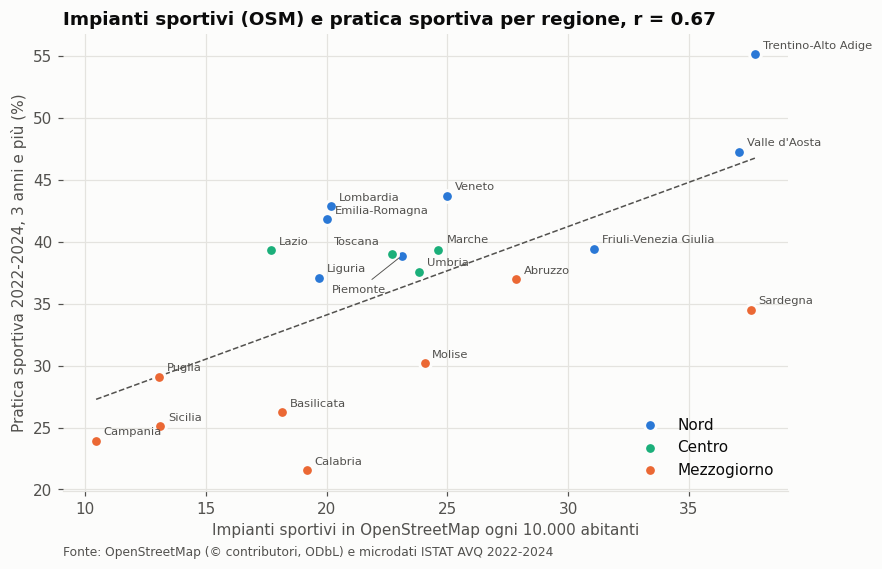

In [4]:
COLORI_AREA = {"Nord": BLU, "Centro": ACQUA, "Mezzogiorno": ARANCIO}
r_p, p_p = stats.pearsonr(reg.impianti_10mila, reg.pratica_sport)
r_s, p_s = stats.spearmanr(reg.impianti_10mila, reg.pratica_sport)
print(f"Pearson r = {r_p:.2f} (p = {p_p:.3f}) | Spearman rho = {r_s:.2f} (p = {p_s:.3f})")

fig, ax = plt.subplots(figsize=(8.5, 5.4))
for area in COLORI_AREA:
    d = reg[reg.area == area]
    ax.scatter(d.impianti_10mila, d.pratica_sport, s=60, color=COLORI_AREA[area], edgecolor=SUPERFICIE,
               linewidth=2, label=area, zorder=3)
SPOSTA = {"Toscana": (-8, 6, "right"), "Piemonte": (-10, -24, "right"), "Marche": (6, 5, "left")}  # evita sovrapposizioni
for nome, r in reg.iterrows():
    dx, dy, ha = SPOSTA.get(nome, (5, 4, "left"))
    freccia = dict(arrowstyle="-", color=TESTO_2, linewidth=0.6) if nome == "Piemonte" else None
    ax.annotate(nome, (r.impianti_10mila, r.pratica_sport), xytext=(dx, dy), textcoords="offset points",
                fontsize=7.5, color=TESTO_2, ha=ha, arrowprops=freccia)
b = np.polyfit(reg.impianti_10mila, reg.pratica_sport, 1)
xs = np.linspace(reg.impianti_10mila.min(), reg.impianti_10mila.max(), 50)
ax.plot(xs, np.polyval(b, xs), color=TESTO_2, linewidth=1, linestyle="--", zorder=2)
ax.set_xlabel("Impianti sportivi in OpenStreetMap ogni 10.000 abitanti")
ax.set_ylabel("Pratica sportiva 2022-2024, 3 anni e più (%)")
ax.set_title(f"Impianti sportivi (OSM) e pratica sportiva per regione, r = {r_p:.2f}")
ax.legend(loc="lower right")
fonte(ax, "Fonte: OpenStreetMap (© contributori, ODbL) e microdati ISTAT AVQ 2022-2024", y=-0.14)
fig.savefig(FIG / "14_osm_impianti_vs_pratica.png")
plt.show()

### Il legame resta all'interno delle macro-aree?
Con 20 regioni un modello deve essere molto semplice. Regressione lineare della pratica sportiva sugli impianti per 10.000 abitanti, con e senza la distinzione Mezzogiorno / Centro-Nord. Errori standard robusti (HC3), adatti a campioni piccoli. Le regioni sono pesate in modo uguale.

In [5]:
reg["mezzogiorno"] = (reg.area == "Mezzogiorno").astype(int)
modelli = {
    "Solo impianti": smf.ols("pratica_sport ~ impianti_10mila", reg).fit(cov_type="HC3"),
    "Impianti + Mezzogiorno": smf.ols("pratica_sport ~ impianti_10mila + mezzogiorno", reg).fit(cov_type="HC3"),
    "Solo Mezzogiorno": smf.ols("pratica_sport ~ mezzogiorno", reg).fit(cov_type="HC3"),
}
tab = pd.DataFrame({
    nome: {"coef. impianti (punti % per +1 impianto/10mila)": m.params.get("impianti_10mila", np.nan),
           "p-value impianti": m.pvalues.get("impianti_10mila", np.nan),
           "coef. Mezzogiorno (punti %)": m.params.get("mezzogiorno", np.nan),
           "p-value Mezzogiorno": m.pvalues.get("mezzogiorno", np.nan),
           "R²": m.rsquared}
    for nome, m in modelli.items()}).T
tab.to_csv(RES / "osm_regressione_regioni.csv")
tab.round(3)

,coef. impianti (punti % per +1 impianto/10mila),p-value impianti,coef. Mezzogiorno (punti %),p-value Mezzogiorno,R²
Solo impianti,0.714,0.005,NaN,NaN,0.446
Impianti + Mezzogiorno,0.498,0.001,-10.934,0.0,0.835
Solo Mezzogiorno,NaN,NaN,-13.328,0.0,0.638


In [6]:
# Lo stesso confronto per i giovani 11-24 anni
r_g, p_g = stats.pearsonr(reg.impianti_10mila, reg.pratica_giovani)
m_g = smf.ols("pratica_giovani ~ impianti_10mila + mezzogiorno", reg).fit(cov_type="HC3")
print(f"Giovani 11-24: r = {r_g:.2f} (p = {p_g:.3f})")
print(f"Con Mezzogiorno: coef. impianti = {m_g.params['impianti_10mila']:.2f} (p = {m_g.pvalues['impianti_10mila']:.3f}), "
      f"coef. Mezzogiorno = {m_g.params['mezzogiorno']:.1f} (p = {m_g.pvalues['mezzogiorno']:.3f})")

Giovani 11-24: r = 0.57 (p = 0.009)
Con Mezzogiorno: coef. impianti = 0.33 (p = 0.001), coef. Mezzogiorno = -9.8 (p = 0.000)


## 3. Lo storico di OpenStreetMap: impianti nuovi o più mappatura?
Il confronto della sezione 2 usa la mappa di **oggi**, mentre l'indagine si riferisce al 2022-2024. Con l'API **ohsome** (HeiGIT, Università di Heidelberg) si ricostruisce lo stato di OSM al 1° gennaio di ogni anno dal 2010 al 2026, regione per regione, usando i confini ufficiali ISTAT (`scripts/scarica_ohsome.py`).

Questo permette due verifiche:
1. **Quanto cresce OSM nel tempo?** Gli impianti sportivi reali in Italia cambiano lentamente. Se in OSM raddoppiano in pochi anni, la crescita misura soprattutto l'**attività dei volontari**: è un errore di non osservazione (copertura incompleta) che cambia nel tempo e tra regioni.
2. **Il risultato regge con dati dello stesso periodo?** Rifacciamo la correlazione con gli impianti mappati al 1° gennaio 2024.

In [7]:
storico = pd.read_csv(ROOT / "data" / "processed" / "ohsome_impianti_storico.csv")
annuale = storico.groupby(["regione", "anno"]).n_elementi.sum().unstack("anno")
annuale.to_csv(RES / "ohsome_impianti_per_anno.csv")
area_di = reg.area.to_dict()
per_area = annuale.groupby(annuale.index.map(area_di)).sum()
italia = annuale.sum()
indice = per_area.div(per_area[2014], axis=0) * 100
print("Impianti mappati in Italia:", {a: int(italia[a]) for a in [2010, 2014, 2018, 2022, 2024, 2026]})
print(f"Crescita 2014 → 2024: Italia {100 * (italia[2024] / italia[2014] - 1):.0f}%")
(per_area.div(per_area[2014], axis=0) * 100)[[2010, 2014, 2018, 2022, 2024, 2026]].round(0)

Impianti mappati in Italia: {2010: 3838, 2014: 38280, 2018: 72592, 2022: 92169, 2024: 101653, 2026: 112965}
Crescita 2014 → 2024: Italia 166%


anno,2010,2014,2018,2022,2024,2026
regione,,,,,,
Centro,10.0,100.0,208.0,282.0,316.0,354.0
Mezzogiorno,5.0,100.0,223.0,292.0,333.0,373.0
Nord,12.0,100.0,173.0,212.0,229.0,252.0


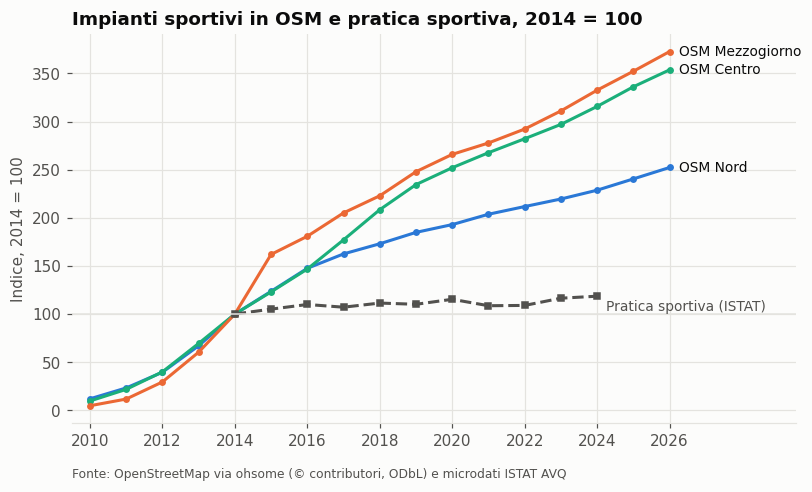

In [8]:
# confronto con la crescita della pratica sportiva nello stesso periodo (AVQ, 3 anni e più)
pratica_anno = (dati[dati.eta_classe != "0-2"].groupby("anno")
                .apply(quota_pesata, include_groups=False))
indice_pratica = pratica_anno / pratica_anno[2014] * 100

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for area, colore in COLORI_AREA.items():
    s = indice.loc[area]
    ax.plot(s.index, s.values, color=colore, marker="o", markersize=3.5)
    ax.annotate(f"OSM {area}", (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=TESTO)
ax.plot(indice_pratica.index, indice_pratica.values, color=TESTO_2, linestyle="--", marker="s", markersize=3.5)
ax.annotate("Pratica sportiva (ISTAT)", (indice_pratica.index[-1], indice_pratica.iloc[-1]), xytext=(6, -2),
            textcoords="offset points", va="top", fontsize=9, color=TESTO_2)
ax.axhline(100, color=GRIGLIA, linewidth=1)
ax.set_xlim(2009.5, 2029.5)
ax.set_xticks(range(2010, 2027, 2))
ax.set_ylabel("Indice, 2014 = 100")
ax.set_title("Impianti sportivi in OSM e pratica sportiva, 2014 = 100")
fonte(ax, "Fonte: OpenStreetMap via ohsome (© contributori, ODbL) e microdati ISTAT AVQ", y=-0.14)
fig.savefig(FIG / "19_osm_storico_vs_pratica.png")
plt.show()

In [9]:
# 1) correlazione con gli impianti mappati al 1° gennaio 2024 (stesso periodo dell'indagine)
reg["impianti_10mila_2024"] = annuale[2024] / reg.popolazione * 10_000
r24, p24 = stats.pearsonr(reg.impianti_10mila_2024, reg.pratica_sport)
m24 = smf.ols("pratica_sport ~ impianti_10mila_2024 + mezzogiorno", reg).fit(cov_type="HC3")
print(f"Impianti al 1/1/2024: r = {r24:.2f} (p = {p24:.3f}); con Mezzogiorno coef. = "
      f"{m24.params['impianti_10mila_2024']:.2f} (p = {m24.pvalues['impianti_10mila_2024']:.3f}), "
      f"Mezzogiorno = {m24.params['mezzogiorno']:.1f}")

# 2) le variazioni: le regioni dove OSM è cresciuto di più hanno visto crescere di più la pratica?
pratica_inizio = (dati[(dati.anno <= 2016) & dati.regione.notna() & (dati.eta_classe != "0-2")]
                  .groupby("regione", observed=True).apply(quota_pesata, include_groups=False))
reg["var_pratica"] = reg.pratica_sport - pratica_inizio
reg["crescita_osm"] = 100 * (annuale[2024] / annuale[2015] - 1)
r_var, p_var = stats.pearsonr(reg.crescita_osm, reg.var_pratica)
print(f"Crescita OSM 2015→2024 vs variazione pratica 2014-16→2022-24: r = {r_var:.2f} (p = {p_var:.3f})")

# 3) la mappa è ancora in costruzione? crescita recente 2022→2026
reg["crescita_recente_osm"] = 100 * (annuale[2026] / annuale[2022] - 1)
reg[["area", "crescita_osm", "crescita_recente_osm", "var_pratica"]].sort_values("crescita_osm", ascending=False).round(1)

Impianti al 1/1/2024: r = 0.68 (p = 0.001); con Mezzogiorno coef. = 0.53 (p = 0.003), Mezzogiorno = -10.9
Crescita OSM 2015→2024 vs variazione pratica 2014-16→2022-24: r = 0.28 (p = 0.226)


,area,crescita_osm,crescita_recente_osm,var_pratica
regione,,,,
Abruzzo,Mezzogiorno,251.0,59.7,5.7
Lazio,Centro,200.6,23.2,3.5
Marche,Centro,199.4,32.1,4.6
Puglia,Mezzogiorno,188.6,25.9,1.2
Campania,Mezzogiorno,188.2,31.3,4.7
Basilicata,Mezzogiorno,156.0,18.5,2.2
Piemonte,Nord,130.7,28.5,2.4
Calabria,Mezzogiorno,125.7,49.0,-2.5
Valle d'Aosta,Nord,116.1,15.1,2.7


In [10]:
reg.groupby("area")[["crescita_osm", "crescita_recente_osm", "var_pratica"]].mean().round(1)

,crescita_osm,crescita_recente_osm,var_pratica
area,,,
Centro,157.1,26.6,4.4
Mezzogiorno,139.0,29.8,2.2
Nord,86.3,18.7,3.0


## 4. Qualità del dato OSM: cosa stiamo misurando davvero?
Prima di usare una fonte big data per la statistica ufficiale bisogna chiedersi se misura il fenomeno o il modo in cui è stata prodotta.

- **Copertura disomogenea.** In OSM una regione ha tanti impianti se ci sono tanti impianti *e* tanti volontari che li mappano. Le regioni del Nord, più ricche e con comunità OSM più attive, potrebbero risultare più "attrezzate" anche solo perché sono mappate meglio. Questo distorce proprio il confronto Nord-Sud.
- **Definizioni.** Un "campo" può essere un campetto di quartiere, un campo da tennis privato o uno stadio; un centro sportivo può contenere molti campi (doppio conteggio parziale tra le categorie). OSM non dice se un impianto è aperto al pubblico, a pagamento o in uso.
- **Tempo.** OSM è una fotografia di oggi; l'indagine ISTAT si riferisce al 2022-2024.
- **Validazione possibile.** Il censimento degli impianti sportivi di Sport e Salute / CONI permetterebbe di confrontare OSM con un dato ufficiale e stimare la copertura per regione.

Il vantaggio di OSM resta grande: è gratuito, aggiornato in continuo, ha un dettaglio geografico fino al singolo impianto e si scarica in pochi minuti con uno script riproducibile.

## Lettura dei risultati
- **Il legame c'è ed è forte:** le regioni con più impianti mappati per abitante fanno più sport (r = 0,67; Spearman 0,60). Per i giovani di 11-24 anni è un po' più debole (r = 0,57).
- **Resta all'interno delle macro-aree:** a parità di Mezzogiorno / Centro-Nord, un impianto in più ogni 10.000 abitanti è associato a circa mezzo punto percentuale di pratica in più. Il modello con entrambe le variabili spiega l'84% delle differenze tra regioni, contro il 64% della sola distinzione Nord-Sud.
- **Ma spiega solo una parte del divario Nord-Sud:** il divario del Mezzogiorno passa da −13,3 a −10,9 punti quando si tiene conto degli impianti. Meno di un quinto del divario si "spiega" con l'offerta di impianti mappati; il resto dipende da altro (reddito, istruzione, abitudini, qualità delle strutture...).
- **Casi da discutere:**
  - la **Sardegna** ha tanti impianti mappati quanto il Trentino-Alto Adige (37-38 ogni 10.000 abitanti) ma una pratica molto più bassa (34,5% contro 55,1%). Può dipendere da come è stata mappata (strutture turistiche, campi privati) o da impianti poco usati;
  - **Lazio e Lombardia** hanno pochi impianti per abitante ma una pratica alta: nelle grandi città gli impianti sono più grandi e molte palestre al chiuso sono mappate peggio.

Questi casi mostrano bene il limite principale di OSM: **misura sia gli impianti sia l'impegno di chi li mappa**. Per usarlo in statistica ufficiale servirebbe una validazione con una fonte censuaria, come il censimento degli impianti di Sport e Salute.

**Lo storico di OSM (sezione 3)**
- **OSM cresce molto più della realtà.** Gli impianti sportivi mappati in Italia passano da 3.838 nel 2010 a 38.280 nel 2014 e a 101.653 nel 2024 (+166% in dieci anni), mentre la pratica sportiva cresce del 19% e gli impianti reali cambiano lentamente. La crescita misura soprattutto **l'attività dei volontari**, non nuove strutture.
- **La copertura è diversa tra territori e cambia nel tempo.** Dal 2014 Centro e Mezzogiorno crescono più del Nord (indice 2024: 316 e 333 contro 229): stanno recuperando un ritardo di mappatura. È un errore di non osservazione (copertura) che non è costante, quindi distorce i confronti nel tempo e nello spazio.
- **Il caso Sardegna si spiega così:** tra il 2014 e il 2015 i suoi impianti mappati passano da 1.745 a 4.690 in un anno (i campi da 1.382 a 3.791), poi restano quasi fermi (+17% dal 2015 al 2024). È il segno tipico di un caricamento in blocco da una fonte esterna (*import*), da verificare nella cronologia di OSM: la Sardegna è mappata in modo più completo delle altre regioni, e per questo sembra avere tanti impianti.
- **Il risultato principale regge** usando gli impianti mappati al 1° gennaio 2024, cioè nello stesso periodo dell'indagine: r = 0,68 e, a parità di Mezzogiorno, +0,53 punti di pratica per ogni impianto in più ogni 10.000 abitanti.
- **Le variazioni non sono collegate:** le regioni in cui OSM è cresciuto di più dal 2015 non sono quelle in cui la pratica sportiva è cresciuta di più (r = 0,28, non significativo). OSM è utile per confrontare le regioni in un dato momento, ma **non per misurare cambiamenti nel tempo**, almeno finché la mappa non è completa.
